# Transfer Learning

Using Resnet18

## Import Dependencies

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
import copy

## Configure Device

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Define Data Transforms

In [3]:
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)
    ])
}

# Import Data

In [6]:
data_dir = 'data/hymenoptera_data'

image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x), data_transforms[x]) for x in ['train', 'val']}
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4, shuffle=True, num_workers=0) for x in ['train', 'val']}

dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}
class_names = image_datasets['train'].classes
print(class_names)

['ants', 'bees']


In [8]:
inputs, classes = next(iter(dataloaders['train']))

## Visualize Images

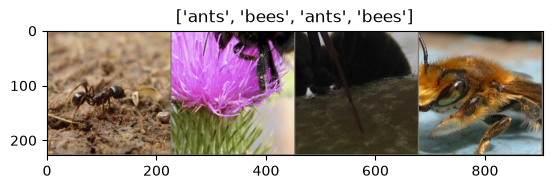

In [9]:
def imshow(inp, title):
    inp = inp.numpy().transpose(1, 2, 0)
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)

    plt.figure()
    plt.imshow(inp)
    plt.title(title)
    plt.show()

out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

## Training Loop

In [11]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    since = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f"Epoch {epoch+1}/{num_epochs}")
        print("-" * 10)

        # each epoch with train and validation phases
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_corrects = 0.0

            # iterate over data
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                # forward pass
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # backward pass -> only in training
                    if phase == 'train':
                        optimizer.zero_grad()
                        loss.backward()
                        optimizer.step()

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]

            print(f'{phase} Loss: {epoch_loss}, Acc: {epoch_acc}')

            # deep copy the model
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

    time_elapsed = time.time() - since

    print(f'Training complete in {time_elapsed // 60}m {time_elapsed % 60}s')
    print(f'Best val Acc: {best_acc}')

    # load best model weights
    model.load_state_dict(best_model_wts)
    return model

## Option1: Finetuning

- Load a pretrained model and reset its final fully-connected layer.
- The weights in the model change.

In [14]:
model = models.resnet18(weights=True)
num_ftrs = model.fc.in_features # get fully connected layer from resnet18
num_ftrs

512

In [15]:
# add another fully connected layer
model.fc = nn.Linear(num_ftrs, 2)
model = model.to(device)

### Define Loss Function, Optimizer and Learning Rate Scheduler

In [16]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=0.001)

In [17]:
# for every 7 epochs, learning rate is multiplied by gamma=0.1
step_lr_scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

### Train to Finetune on New Data

In [18]:
model = train_model(model, criterion, optimizer, step_lr_scheduler, num_epochs=20)

Epoch 1/20
----------
train Loss: 0.5982392528018013, Acc: 0.6926229508196722
val Loss: 0.4669569602199629, Acc: 0.8562091503267975
Epoch 2/20
----------
train Loss: 0.5063369286353471, Acc: 0.7581967213114754
val Loss: 0.3668615491512944, Acc: 0.8562091503267975
Epoch 3/20
----------
train Loss: 0.44362154114441793, Acc: 0.8073770491803279
val Loss: 0.31741468369765996, Acc: 0.9084967320261438
Epoch 4/20
----------
train Loss: 0.47419334068650104, Acc: 0.7581967213114754
val Loss: 0.2592153653648554, Acc: 0.9215686274509804
Epoch 5/20
----------
train Loss: 0.3946088261780192, Acc: 0.8606557377049181
val Loss: 0.24422501385504125, Acc: 0.9150326797385622
Epoch 6/20
----------
train Loss: 0.4254277021181388, Acc: 0.7991803278688525
val Loss: 0.22964017239271425, Acc: 0.934640522875817
Epoch 7/20
----------
train Loss: 0.38410934396698826, Acc: 0.819672131147541
val Loss: 0.21471217166315887, Acc: 0.9411764705882353
Epoch 8/20
----------
train Loss: 0.3659661538654663, Acc: 0.8360655737

## Option 2: ConvNet as Fixed Feature Extractor

- Freeze all the network except the final layer.
- Train only the last layer.
- Only the weights in final layer change.

In [19]:
model_conv = models.resnet18(weights=True)

for param in model_conv.parameters():
    param.requires_grad = False

num_ftrs = model_conv.fc.in_features

model_conv.fc = nn.Linear(num_ftrs, 2)
model_conv = model_conv.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_conv.parameters(), lr=0.001, momentum=0.9)
step_lr_scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

model_conv = train_model(model_conv, criterion, optimizer, step_lr_scheduler, num_epochs=25)

Epoch 1/25
----------
train Loss: 0.5672294030912587, Acc: 0.7049180327868853
val Loss: 0.2409467288092071, Acc: 0.9084967320261438
Epoch 2/25
----------
train Loss: 0.46095484849370894, Acc: 0.8155737704918034
val Loss: 0.17487289393746774, Acc: 0.9477124183006537
Epoch 3/25
----------
train Loss: 0.5600172485850874, Acc: 0.75
val Loss: 0.19960303083549139, Acc: 0.9150326797385622
Epoch 4/25
----------
train Loss: 0.3945309371977556, Acc: 0.819672131147541
val Loss: 0.17468003339432422, Acc: 0.954248366013072
Epoch 5/25
----------
train Loss: 0.38419176905309077, Acc: 0.8442622950819673
val Loss: 0.3769960848103259, Acc: 0.8366013071895425
Epoch 6/25
----------
train Loss: 0.5403390813496758, Acc: 0.7745901639344263
val Loss: 0.18339959681764537, Acc: 0.954248366013072
Epoch 7/25
----------
train Loss: 0.5068648714785937, Acc: 0.7622950819672132
val Loss: 0.30598992170169464, Acc: 0.9084967320261438
Epoch 8/25
----------
train Loss: 0.3956187983486252, Acc: 0.8237704918032788
val Loss